# Numerical Optimization of gut-immune interactions

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import fsolve
from math import erf
import numba as nb
import multiprocessing as mp
from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import mpltern
from mpltern.datasets import get_triangular_grid

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

### A. Define model parameters and useful functions

In [37]:
# Define model parameters

##  microbes ##
nG = 20
A = 0.0*np.random.binomial(n = 1, p = 0.2, size = (nG,nG)) # species competition matrix
A[np.arange(0,nG),np.arange(0,nG)] = 0.0
dG = 1*np.ones(nG) # microbial death rate
q = np.random.dirichlet(np.ones(nG)) #0.01*np.random.binomial(n = 2, p = 0.7, size = nG) # immigration rate of microbes into the gut
mu = np.zeros(nG) # rates of breaching gut epithelium
mu = np.random.binomial(n = 1, p = 0.25, size=(nG))

## resources ##
nR = 3
w = 0.1*np.ones(nR) # resource clearance rate
E = 1 # metabolic capacity
C = E*np.random.dirichlet(np.ones(nR), size = nG) # resource utilization matrix
K = np.ones(nR) # resource input rate
v = np.ones(nR) # resource value
S = C.dot(C.T) # species similarity matrix

## antibodies + inflammation ##
na = nG
sigma_lam = 1/3
lam = C #E*np.random.dirichlet(np.ones(nR), size = na)
lam_max = 1.0 # strength of inflammatory pressure
F = lam_max*np.vstack([np.array([np.exp(-np.linalg.norm(C_Gi - lam_Gj)/sigma_lam**2) for C_Gi in C]) for lam_Gj in C]) # antibody + inflammation cross-reactivity: F_i,a = f_a,i
b_lam = 1.0
d_lam = 0.1

## benefits ##
nB = 3
D0 = np.random.binomial(n = 1, p = 0.25, size=(nB,nG)).dot(np.diag(1-mu)) # microbe benefit matrix
beta = 0.5*np.ones(nB) # scaling of microbe benefit relative to harm
u = np.ones(nB) # decay rate of benefits

## Treg receptors ##
ngam = nG
sigma_gam = 1/2
gam = C #E*np.random.dirichlet(np.ones(nR), size = ngam)
gam_max = 1
M = 1 - gam_max*np.vstack([np.array([np.exp(-np.linalg.norm(C_Gi - gam_j*(mu[j] == 0))/sigma_gam**2) for C_Gi in C]) for j, gam_j in enumerate(gam)]) # Treg cross-reactivity: M_i,a = m_r,a
b_gam = 1.0
d_gam = 0.1

In [38]:
# Define functions
def H(G, mu):
    # purpose: model harm caused by gut invasion
    return G*mu


def G_ss(P, gam):
    # Purpose: compute the steady state of the general nonlinear system of equations
    L = lam*np.diag((np.ones(nG) - M.dot(gam))*(np.ones(nG) - F.dot(P))*mu)
    guess = np.maximum(np.linalg.lstsq(C.T, K*E*v/dG[0] - w, rcond = None)[0],0)
    
    def func(G):
        return np.diag(-Lam(gam).dot(G) + C.dot(K/(w + C.T.dot(G))) + A.dot(G) - dG).dot(G)
    
    root = fsolve(func, guess)
    
    return np.maximum(root,0)

def G_ss_perm(P, gam):
    # Purpose: compute the steady state of the general nonlinear system under the assumption that col(M) is in col(C)
    # i.e. under the assumption that tolerance coverage is consistent with with resource strategies
    L = lam*np.diag((np.ones(nG) - M.dot(gam))*(np.ones(nG) - F.dot(P))*mu)
    guess = np.maximum(np.linalg.lstsq(C.T, K*E*v/dG[0] - w, rcond = None)[0],0)
    
    def func(G):
        return np.diag(C.dot(np.linalg.lstsq(C, -Lam(gam).dot(G), rcond = None)[0]) + C.dot(K/(w + C.T.dot(G))) + A.dot(G) - dG).dot(G)
    
    root = fsolve(func, guess)
    
    return np.maximum(root,0)

def B_ss(P,gam, G):
    out =  np.diag(1/u).dot(D0).dot(G)
    return out

### B. Simulate microbe-immune dynamics

In [39]:
# Simulate microbe dynamics
from scipy.integrate import odeint

# time points
sim_dur = 300
q_t = np.random.binomial(n = 1, p = 0.0, size = nG)
t_infect = 0.5
lam_max = 1.0
gam_max = 1.0

# function that returns dx/dt = A x 
def model(x, t, Lam, Gam, lam_max, gam_max, imm_dyn = "static"):
    R = x[0:nR]
    G = x[nR:nR+nG]
    B = x[nR+nG:nR+nG+nB]
    lam_eff = x[nR+nG+nB:nR+nG+nB+nG]
    gam_eff = x[nR+nG+nB+nG:nR+nG+nB+nG+nG]
    

    F = np.vstack([lam_eff*np.array([np.exp(-np.linalg.norm(C_Gi - lam_j)/sigma_lam**2) for C_Gi in C]) for j,lam_j in enumerate(Lam)]) # antibody + inflammation cross-reactivity: F_i,a = f_a,i
    M = 1 - np.vstack([gam_eff[j]*np.array([np.exp(-np.linalg.norm(C_Gi - gam_j*(mu[j] == 0))/sigma_gam**2) for C_Gi in C]) for j, gam_j in enumerate(Gam)]) # Treg cross-reactivity: M_i,a = m_r,a

    dRdt = K - w*R - C.T.dot(G)*R
    dGdt = (C.dot(R) + (A - F*M).dot(G) - dG).dot(np.diag(G*(G > 0)))
    dBdt = D0.dot(G) - u*B
    
    if imm_dyn == "static":
        d_lam_eff_dt = np.zeros(nG)
        d_gam_eff_dt = np.zeros(nG)
    elif imm_dyn == "dynamic":
        d_lam_eff_dt = (b_lam*(lam_max - lam_eff)*(mu*G) - d_lam*lam_eff)*(lam_eff <= lam_max)
        d_gam_eff_dt = (b_gam*(gam_max - gam_eff)*(beta.dot(B) - mu*G) - d_gam*gam_eff)*(gam_eff <= gam_max)*(gam_eff >= 0)
        
    return list(np.concatenate((dRdt, dGdt, dBdt, d_lam_eff_dt, d_gam_eff_dt)).ravel())

# initial condition
x0 = np.hstack((np.ones(nR), 0.1*np.ones(nG), np.zeros(nB), 0.01*np.ones(nG), 0.01*np.ones(nG)))
t = np.linspace(0, sim_dur, num = 1000)

# solve ODE
x_model = odeint(model,list(x0),t, args = (C, C, lam_max, gam_max, "dynamic"))
R = x_model[:,:nR]
G = x_model[:,nR:nR+nG]
B = x_model[:,nR+nG:nR+nG+nB]
Lam = x_model[:,nR+nG+nB:nR+nG+nB+nG]
Gam =x_model[:,nR+nG+nB+nG:nR+nG+nB+nG+nG]

imm_load = (M*F).dot(G.T).T

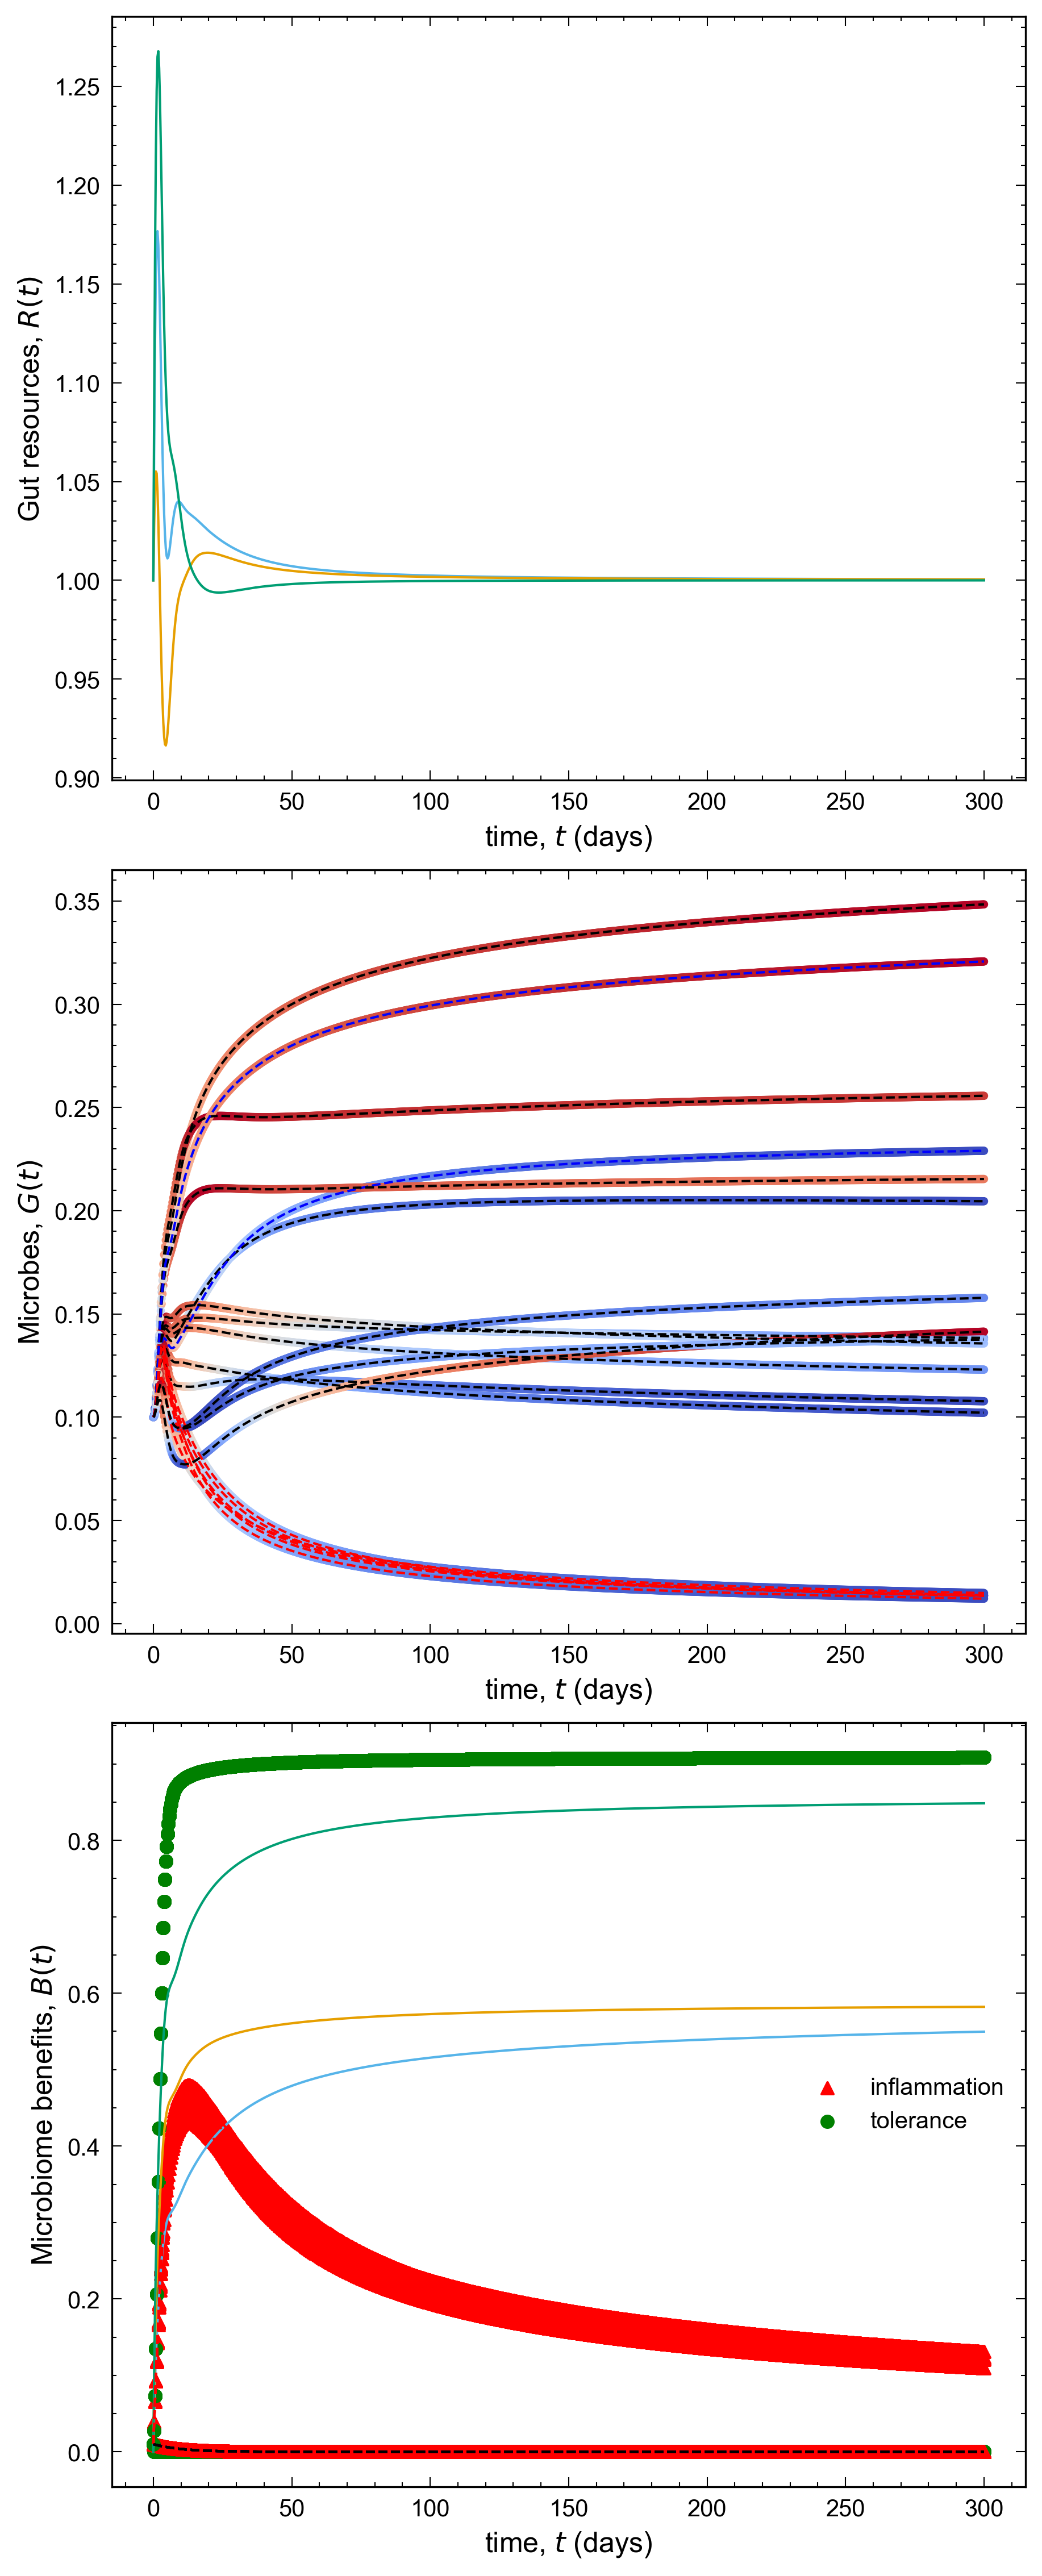

In [40]:
# Plot simulated dynamics
fig, (ax1, ax2, ax3) = plt.subplots(3,1, dpi = 150, constrained_layout=True, sharex = False, figsize=(6,15))

ax1.plot(t, R)
#ax1.axvline(x = t_infect*sim_dur, color = 'k', linestyle = '-.')
#ax1.axhline(y = dG[0]/E*1/v[0], color = 'k', linestyle = '-.')
#[ax1.axhline(y = i, color = 'k', linestyle = '-.') for i in k/(C.T.dot(Gss_nlinR) + w)]
ax1.set(xlabel=r'time, $t$ (days)', ylabel=r'Gut resources, $R(t)$')

for j in np.arange(nG):
    ax2.scatter(t, G[:,j], marker ='.', c = imm_load[:,j], cmap='coolwarm') #, norm=mpl.colors.LogNorm())
    if mu[j] > 0:
        ax2.plot(t, G[:,j], color = 'red', linestyle = '--') # gut breaching bacteria
    if D0[0,j] > 0:
        ax2.plot(t, G[:,j], color = 'blue', linestyle = '--') # non-gut breaching, non-beneficial bacteria
    if D0[0,j] == 0 and mu[j] == 0:
        ax2.plot(t, G[:,j], color = 'black', linestyle = '--') # non-gut breaching, non-beneficial bacteria

#[ax2.axhline(y=i, linestyle='--') for i in Gss_nlinR]
#ax2.axvline(x = t_infect*sim_dur, color = 'k', linestyle = '-.')
ax2.set(xlabel=r'time, $t$ (days)', ylabel=r'Microbes, $G(t)$')

ax3.plot(t, B)
for j in np.arange(nG):
    ax3.scatter(t, Lam[:,j], marker = "^", color = 'red', label = "inflammation" if j == 0 else "")
    if mu[j] > 0:
        ax3.plot(t, Lam[:,j], color = 'red', linestyle = '--') # gut breaching bacteria
    if D0[0,j] > 0:
        ax3.plot(t, Lam[:,j], color = 'blue', linestyle = '--') # non-gut breaching, non-beneficial bacteria
    if D0[0,j] == 0 and mu[j] == 0:
        ax3.plot(t, Lam[:,j], color = 'black', linestyle = '--') # non-gut breaching, non-beneficial bacteria
    ax3.scatter(t, Gam[:,j], marker = "o", color = 'green', label = "tolerance" if j == 0 else "")
#ax3.axvline(x = t_infect*sim_dur, color = 'k', linestyle = '-.')
ax3.set(xlabel=r'time, $t$ (days)', ylabel=r'Microbiome benefits, $B(t)$')
ax3.legend()

plt.savefig('_figs/gut_w_immune_series'+'.png', dpi=300, bbox_inches='tight')

In [113]:
# harm, benefits and net utility
gams = [np.diag(out).dot(C) for out in np.array(list(itertools.product([0,1], repeat = nG)))]

opt_out = Parallel(n_jobs=8, batch_size = max(int(len(gams)/8),1))(delayed(odeint)(model,
                                                                                       list(x0), 
                                                                                       t = np.linspace(0,sim_dur, num = 1000), 
                                                                                       args = (C, 
                                                                                               gam, 
                                                                                               lam_max, 
                                                                                               gam_max))
                                                    for gam in gams)

utility, benefit, harm = [], [], []
for out in opt_out:
    R = out[:,:nR]
    G = out[:,nR:nR+nG]
    B = out[:,nR+nG:]
    
    benefit.append(np.sum(B)/sim_dur)
    harm.append(np.sum(G.dot(np.diag(mu)))/sim_dur)
    utility.append((np.sum(B)-np.sum(G.dot(np.diag(mu))))/sim_dur)

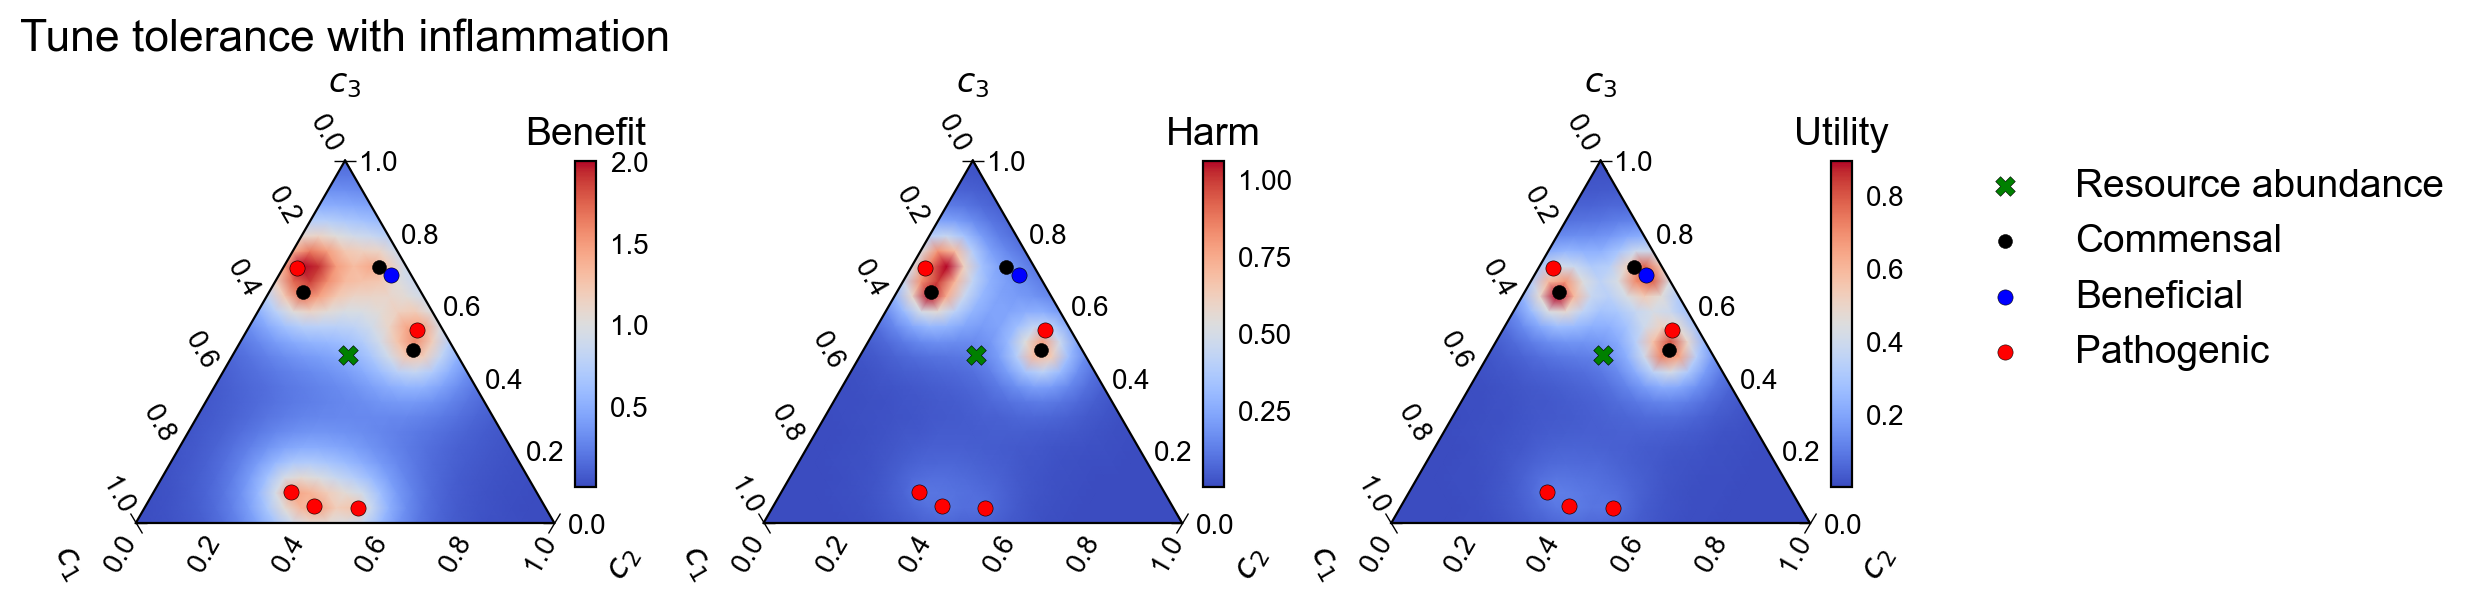

In [137]:
fig = plt.figure(figsize=(10.8, 4.8))
fig.subplots_adjust(left=0.075, right=0.85, wspace=0.5)

ax1 = fig.add_subplot(1, 3, 1, projection="ternary")
ax2 = fig.add_subplot(1, 3, 2, projection="ternary")
ax3 = fig.add_subplot(1, 3, 3, projection="ternary")

grid = np.array(E*get_triangular_grid(25)).T #E*np.concatenate((np.random.dirichlet(np.ones(nR), size = 1000),np.eye(N=nR)))
t,l,r = grid.T

# optimize immune response for harm, benefits and net utility
utility_tol, benefit_tol, harm_tol = [], [], []

gams = [np.diag(out).dot(C) for out in np.array(list(itertools.product([0,1], repeat = nG)))]

opt_out = Parallel(n_jobs=8, batch_size = max(int(len(gams)/8),1))(delayed(odeint)(model,
                                                                                       list(x0), 
                                                                                       t = np.linspace(0,sim_dur, num = 1000), 
                                                                                       args = (C, 
                                                                                               gam, 
                                                                                               lam_max, 
                                                                                               gam_max))
                                                    for gam in gams)

utility, benefit, harm = [], [], []
for out in opt_out:
    R = out[:,:nR]
    G = out[:,nR:nR+nG]
    B = out[:,nR+nG:]
    
    benefit.append(np.sum(B)/sim_dur)
    harm.append(np.sum(G.dot(np.diag(mu)))/sim_dur)
    utility.append((np.sum(B)-np.sum(G.dot(np.diag(mu))))/sim_dur)
    
lam_opt = C
gam_opt_ben, gam_opt_harm, gam_opt_util = gams[np.argmax(benefit)], gams[np.argmin(harm)], gams[np.argmax(utility)]

ben_inflamm = [np.sum(np.array([lam_max*np.exp(-np.linalg.norm(grid_i - lam_j)/sigma_lam**2) for lam_j in lam_opt])*np.array([1 - lam_max*np.exp(-np.linalg.norm(grid_i - gam_j)/sigma_gam**2) for gam_j in gam_opt_ben])) for grid_i in grid]
harm_inflamm = [np.sum(np.array([lam_max*np.exp(-np.linalg.norm(grid_i - lam_j)/sigma_lam**2) for lam_j in lam_opt])*np.array([lam_max*np.exp(-np.linalg.norm(grid_i - gam_j)/sigma_gam**2) for gam_j in gam_opt_harm])) for grid_i in grid]
util_inflamm = [np.sum(np.array([lam_max*np.exp(-np.linalg.norm(grid_i - lam_j)/sigma_lam**2) for lam_j in lam_opt])*np.array([lam_max*np.exp(-np.linalg.norm(grid_i - gam_j)/sigma_gam**2) for gam_j in gam_opt_util])) for grid_i in grid]

# plot results
tpc1 = ax1.tripcolor(t, l, r, ben_inflamm, shading='gouraud', rasterized=True, cmap='coolwarm')
tpc2 = ax2.tripcolor(t, l, r, harm_inflamm, shading='gouraud', rasterized=True, cmap='coolwarm')
tpc3 = ax3.tripcolor(t, l, r, util_inflamm, shading='gouraud', rasterized=True, cmap='coolwarm')

cax1 = ax1.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax1.transAxes)
cb1 = fig.colorbar(tpc1, cax = cax1, shrink = 0.6, pad = 0.075)
cb1.ax.set_title('Benefit')

cax2 = ax2.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax2.transAxes)
cb2 = fig.colorbar(tpc2, cax = cax2, shrink = 0.6, pad = 0.075)
cb2.ax.set_title('Harm')

cax3 = ax3.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax3.transAxes)
cb3 = fig.colorbar(tpc3, cax = cax3, shrink = 0.6, pad = 0.075)
cb3.ax.set_title('Utility')

# plot resource supply
t, l, r = K
ax1.scatter(t, l, r, label="Resource abundance", color = "green", marker = "X", s = 50, edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Resource abundance", color = "green", marker = "X", s = 50, edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Resource abundance", color = "green", marker = "X", s = 50, edgecolor = 'k', linewidth = 0.2)

# plot commensals
t, l, r = C[1:].T
ax1.scatter(t, l, r, label="Commensal", color = "black", edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Commensal", color = "black", edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Commensal", color = "black", edgecolor = 'k', linewidth = 0.2)

# plot beneficials
t, l, r = C[np.sum(D0, axis = 0) > 0].T
ax1.scatter(t, l, r, label="Beneficial", color = "blue", s = 30, edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Beneficial", color = "blue", s = 30, edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Beneficial", color = "blue", s = 30, edgecolor = 'k', linewidth = 0.2)

# plot extinctions
for k, c in enumerate(C):
    if G[-1,k] <= 0:
        t, l, r = c
        ax1.scatter(t, l, r, alpha=0.5, color = "red", marker = "X", edgecolor = 'k', linewidth = 0.2)
        ax2.scatter(t, l, r, alpha=0.5, color = "red", marker = "X", edgecolor = 'k', linewidth = 0.2)
        ax3.scatter(t, l, r, alpha=0.5, color = "red", marker = "X", edgecolor = 'k', linewidth = 0.2)
    

# plot pathogens
t, l, r = C[mu > 0].T
ax1.scatter(t, l, r, label="Pathogenic", color = "red", s = 30, edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Pathogenic", color = "red", s = 30, edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Pathogenic", color = "red", s = 30, edgecolor = 'k', linewidth = 0.2)

ax3.legend(loc='center right', bbox_to_anchor=(2.6, 0.7), fontsize = 14)
ax1.set_title("Tune tolerance with inflammation", fontsize = 16)

ax1.set_llabel(r'$c_1$')
ax1.set_rlabel(r'$c_2$')
ax1.set_tlabel(r'$c_3$')

ax2.set_llabel(r'$c_1$')
ax2.set_rlabel(r'$c_2$')
ax2.set_tlabel(r'$c_3$')

ax3.set_llabel(r'$c_1$')
ax3.set_rlabel(r'$c_2$')
ax3.set_tlabel(r'$c_3$')

plt.show()
fig.savefig('_figs/gut_w_immune_infl_tol'+'.png', dpi=300, bbox_inches='tight')

In [141]:
# harm, benefits and net utility
# Define base grid
grid = np.array(E*get_triangular_grid(20)).T
m1,n1 = grid.shape
m2,n2 = grid.shape
opt_grid = np.zeros((m1,m2,n1+n2),dtype=float)
opt_grid[:,:,:n1] = grid[:,None,:]
opt_grid[:,:,n1:] = grid
opt_grid.shape = (m1*m2,-1)

# Search over grid for optimality
opt_out = Parallel(n_jobs=8, batch_size = max(int(len(opt_grid)/8),1))(delayed(odeint)(model,
                                                                                       list(x0), 
                                                                                       t = np.linspace(0,sim_dur, num = 1000), 
                                                                                       args = (C[0], 
                                                                                               grid_i[0:3], 
                                                                                               grid_i[3:], 
                                                                                               lam_max, 
                                                                                               1.0*a_max, 
                                                                                               1.0*gam_max,
                                                                                               eco_ctrl))
                                                    for grid_i in opt_grid)

utility_avoid_tol, benefit_avoid_tol, harm_avoid_tol = [], [], []
for out in opt_out:
    R = out[:,:nR]
    G = out[:,nR:nR+nG]
    B = out[:,nR+nG:]
    
    benefit_avoid_tol.append(np.sum(B)/sim_dur)
    harm_avoid_tol.append(np.sum(G.dot(np.diag(mu)))/sim_dur)
    utility_avoid_tol.append((np.sum(B)-np.sum(G.dot(np.diag(mu))))/sim_dur)

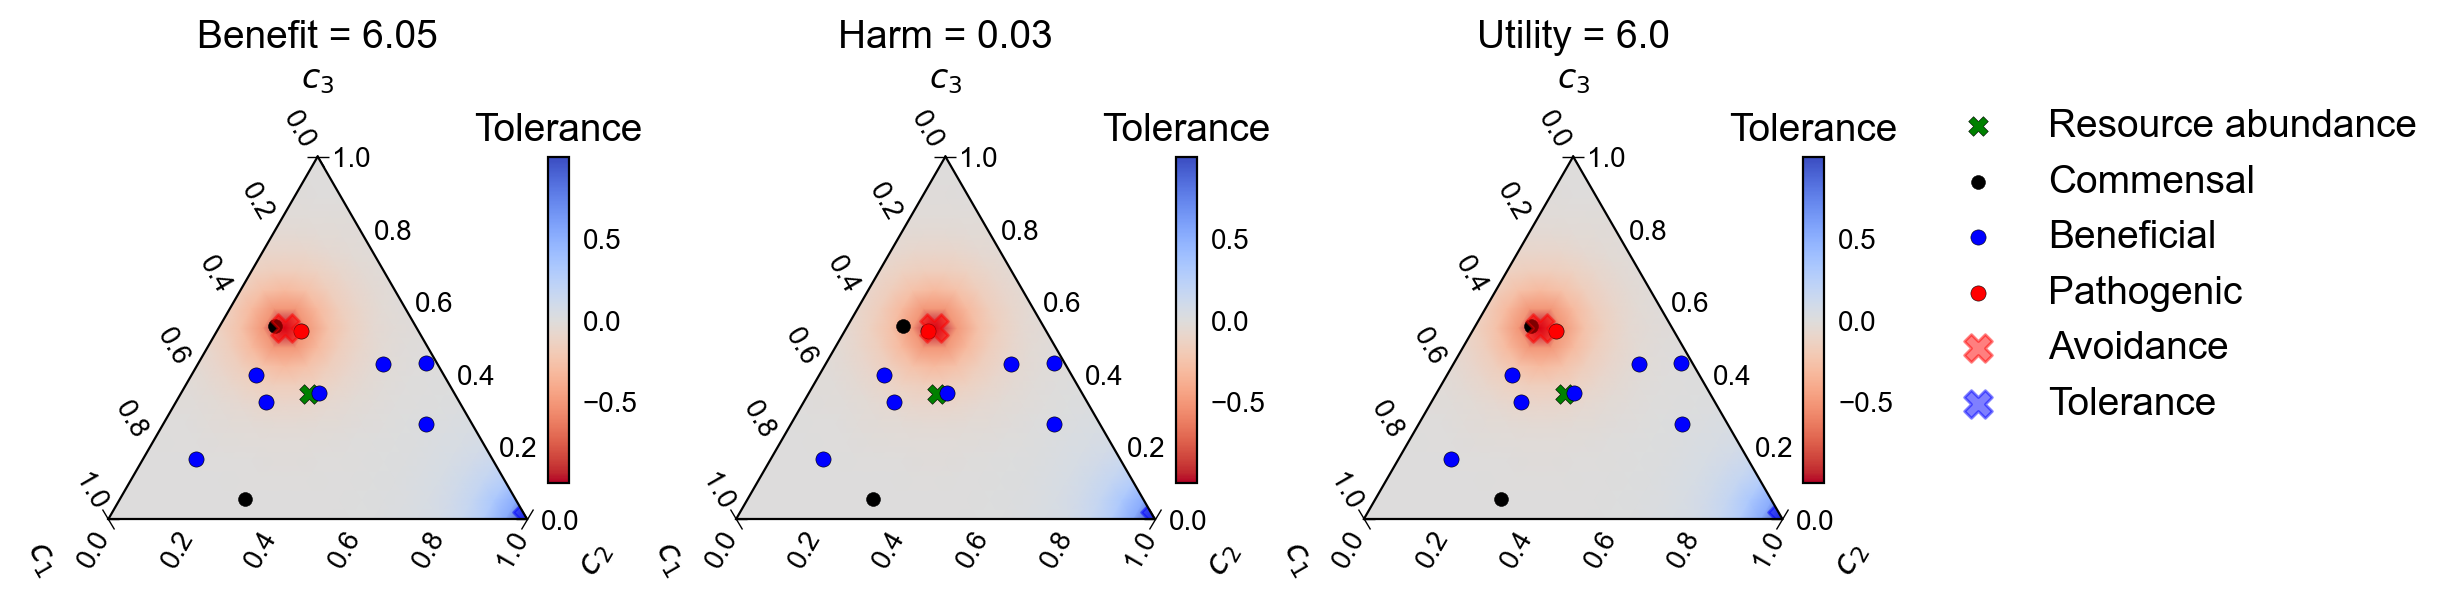

In [142]:
fig = plt.figure(figsize=(10.8, 4.8))
fig.subplots_adjust(left=0.075, right=0.85, wspace=0.5)

ax1 = fig.add_subplot(1, 3, 1, projection="ternary")
ax2 = fig.add_subplot(1, 3, 2, projection="ternary")
ax3 = fig.add_subplot(1, 3, 3, projection="ternary")

# Avoidance and tolerance fld
t,l,r = grid.T

utility_fld = [-np.exp(-np.linalg.norm(grid_i - opt_grid[np.argmax(utility_avoid_tol), 0:3])/sigma_lam**2) + np.exp(-np.linalg.norm(grid_i - opt_grid[np.argmax(utility_avoid_tol), 3:])/sigma_gam**2) for grid_i in grid]
benefit_fld = [-np.exp(-np.linalg.norm(grid_i - opt_grid[np.argmax(benefit_avoid_tol), 0:3])/sigma_lam**2) + np.exp(-np.linalg.norm(grid_i - opt_grid[np.argmax(benefit_avoid_tol), 3:])/sigma_gam**2) for grid_i in grid]
harm_fld = [-np.exp(-np.linalg.norm(grid_i - opt_grid[np.argmin(harm_avoid_tol), 0:3])/sigma_lam**2) + np.exp(-np.linalg.norm(grid_i - opt_grid[np.argmin(harm_avoid_tol), 3:])/sigma_gam**2) for grid_i in grid]

tpc1 = ax1.tripcolor(t, l, r, benefit_fld, shading='gouraud', rasterized=True, cmap='coolwarm_r')
tpc2 = ax2.tripcolor(t, l, r, harm_fld, shading='gouraud', rasterized=True, cmap='coolwarm_r')
tpc3 = ax3.tripcolor(t, l, r, utility_fld, shading='gouraud', rasterized=True, cmap='coolwarm_r')

cax1 = ax1.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax1.transAxes)
cb1 = fig.colorbar(tpc1, cax = cax1, shrink = 0.6, pad = 0.075)
cb1.ax.set_title('Tolerance')

cax2 = ax2.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax2.transAxes)
cb2 = fig.colorbar(tpc2, cax = cax2, shrink = 0.6, pad = 0.075)
cb2.ax.set_title('Tolerance')

cax3 = ax3.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax3.transAxes)
cb3 = fig.colorbar(tpc3, cax = cax3, shrink = 0.6, pad = 0.075)
cb3.ax.set_title('Tolerance')

# plot resource supply
t, l, r = K
ax1.scatter(t, l, r, label="Resource abundance", color = "green", marker = "X", s = 50, edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Resource abundance", color = "green", marker = "X", s = 50, edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Resource abundance", color = "green", marker = "X", s = 50, edgecolor = 'k', linewidth = 0.2)

# plot commensals
t, l, r = C[1:].T
ax1.scatter(t, l, r, label="Commensal", color = "black", edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Commensal", color = "black", edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Commensal", color = "black", edgecolor = 'k', linewidth = 0.2)

# plot beneficials
t, l, r = C[np.sum(D0, axis = 0) > 0].T
ax1.scatter(t, l, r, label="Beneficial", color = "blue", s = 30, edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Beneficial", color = "blue", s = 30, edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Beneficial", color = "blue", s = 30, edgecolor = 'k', linewidth = 0.2)

# plot extinctions
for k, c in enumerate(C[1:]):
    if G[-1,k+1] <= 0:
        t, l, r = c
        ax1.scatter(t, l, r, alpha=0.5, color = "red", marker = "X", edgecolor = 'k', linewidth = 0.2)
        ax2.scatter(t, l, r, alpha=0.5, color = "red", marker = "X", edgecolor = 'k', linewidth = 0.2)
        ax3.scatter(t, l, r, alpha=0.5, color = "red", marker = "X", edgecolor = 'k', linewidth = 0.2)

# plot pathogens
t, l, r = C[0].T
ax1.scatter(t, l, r, label="Pathogenic", color = "red", s = 30, edgecolor = 'k', linewidth = 0.2)
ax2.scatter(t, l, r, label="Pathogenic", color = "red", s = 30, edgecolor = 'k', linewidth = 0.2)
ax3.scatter(t, l, r, label="Pathogenic", color = "red", s = 30, edgecolor = 'k', linewidth = 0.2)

# plot avoidance and tolerance
t, l, r = opt_grid[np.argmax(benefit_avoid_tol), 0:3]
ax1.scatter(t, l, r, alpha=0.5, label="Avoidance", marker = "X", color = "red", s = 100)
t, l, r = opt_grid[np.argmax(benefit_avoid_tol), 3:]
ax1.scatter(t, l, r, alpha=0.5, label="Tolerance", marker = "X", color = "blue", s = 100)

t, l, r = opt_grid[np.argmin(harm_avoid_tol), 0:3]
ax2.scatter(t, l, r, alpha=0.5, label="Avoidance", marker = "X", color = "red", s = 100)
t, l, r = opt_grid[np.argmin(harm_avoid_tol), 3:]
ax2.scatter(t, l, r, alpha=0.5, label="Tolerance", marker = "X", color = "blue", s = 100)

t, l, r = opt_grid[np.argmax(utility_avoid_tol), 0:3]
ax3.scatter(t, l, r, alpha=0.5, label="Avoidance", marker = "X", color = "red", s = 100)
t, l, r = opt_grid[np.argmax(utility_avoid_tol), 3:]
ax3.scatter(t, l, r, alpha=0.5, label="Tolerance", marker = "X", color = "blue", s = 100)

ax3.legend(loc='center right', bbox_to_anchor=(2.6, 0.7), fontsize = 14)
ax1.set_title("Benefit = "+str(np.round(np.max(benefit_avoid_tol),2)))
ax2.set_title("Harm = "+str(np.round(np.min(harm_avoid_tol),2)))
ax3.set_title("Utility = "+str(np.round(np.max(utility_avoid_tol),2)))

ax1.set_llabel(r'$c_1$')
ax1.set_rlabel(r'$c_2$')
ax1.set_tlabel(r'$c_3$')

ax2.set_llabel(r'$c_1$')
ax2.set_rlabel(r'$c_2$')
ax2.set_tlabel(r'$c_3$')

ax3.set_llabel(r'$c_1$')
ax3.set_rlabel(r'$c_2$')
ax3.set_tlabel(r'$c_3$')

plt.show()
fig.savefig('_figs/gut_w_avoid_tol'+'.png', dpi=300, bbox_inches='tight')

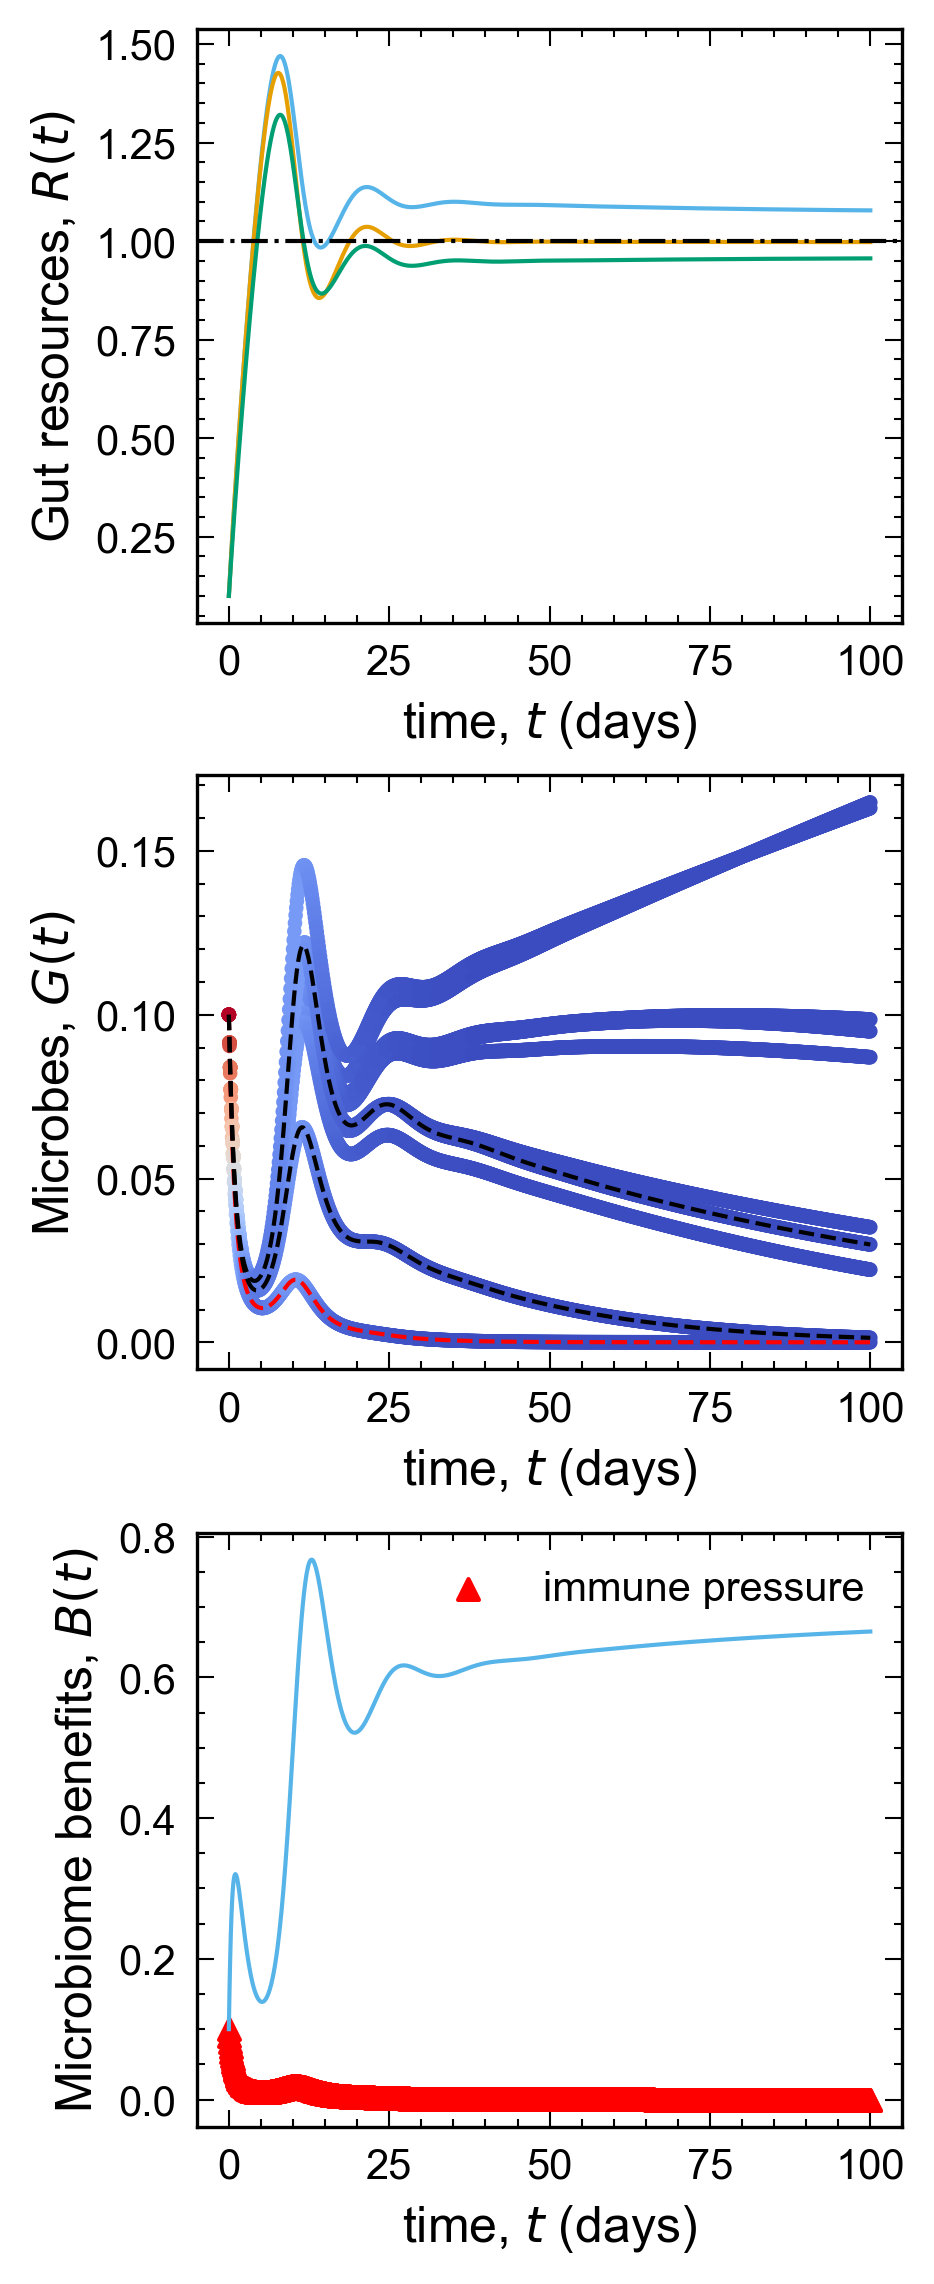

In [156]:
# solve ODE
t = np.linspace(0, sim_dur, num = 1000)
x_model = odeint(model,list(x0),t, args = (C[0], 
                                           opt_grid[np.argmin(harm_avoid_tol), 0:3], 
                                           opt_grid[np.argmin(harm_avoid_tol), 3:], lam_max, 1.0*a_max, 1.0*gam_max, eco_ctrl))
R = x_model[:,:nR]
G = x_model[:,nR:nR+nG]
B = x_model[:,nR+nG:]
Lam = lam_max*np.diag(np.ones(nG) - gam_max*M.dot(np.ones(ngam)/ngam)).dot(np.outer(np.array([np.exp(-np.linalg.norm(C_Gi - C[0])/sigma_inflam**2) for C_Gi in C]), mu))

imm_load = Lam.dot(G.T).T

# Plot
# Plot simulated dynamics
fig, (ax1, ax2, ax3) = plt.subplots(3,1, dpi = 150, constrained_layout=True, sharex = False, figsize=(3,7.5))

ax1.plot(t, R)
#ax1.axvline(x = t_infect*sim_dur, color = 'k', linestyle = '-.')
ax1.axhline(y = dG[0]/E*1/v[0], color = 'k', linestyle = '-.')
ax1.set(xlabel=r'time, $t$ (days)', ylabel=r'Gut resources, $R(t)$')

for j in np.arange(nG):
    ax2.scatter(t, G[:,j], marker ='.', c = imm_load[:,j], cmap='coolwarm') #, norm=mpl.colors.LogNorm())
    if mu[j] == 1:
        ax2.plot(t, G[:,j], color = 'red', linestyle = '--') # gut breaching bacteria
    if D0[0,j] == 0 and mu[j] == 0:
        ax2.plot(t, G[:,j], color = 'black', linestyle = '--') # non-gut breaching, non-beneficial bacteria

ax2.set(xlabel=r'time, $t$ (days)', ylabel=r'Microbes, $G(t)$')

ax3.plot(t, B)
ax3.scatter(t, G.dot((np.ones(nG) - F.dot(P0))*mu), marker = "^", color = 'red', label = "immune pressure")
ax3.set(xlabel=r'time, $t$ (days)', ylabel=r'Microbiome benefits, $B(t)$')
ax3.legend()

plt.savefig('_figs/gut_w_immune_series_optimized'+'.png', dpi=300, bbox_inches='tight')

### C. Find optimal repertoire and tolerance level

In [33]:
# Run optimization for a test system
reltol = 1e-8
popt = minimize(objective, pg0=np.append(P0,gam0), reltol=reltol,
                             maxiters=2e4, show_progress=True,
                             nboundupdate=1e4)

print(popt)

NameError: name 'minimize' is not defined

In [ ]:
#print(F.dot(np.ones(na)/na))
print(np.corrcoef(F.dot(popt[:-1]),mu))

In [ ]:
# Next think about a better stopping condition than just reaching the lower bound. 
# Also figure out a way to make sense of the results. Which antibodies get preferred and how does it translate into protection.

In [ ]:
g_ss(P0,gam0)*mu

In [ ]:
# Implement proximal gradient optimization for repertoire: https://pypi.org/project/pyproximal/
def project(pg, mask=None):
    """ Take a vector pg (with possible nonnegative entries and non-normalized)
        and project it onto the unit simplex. Take value gamma and project it onto an interval
        mask:   do not project these entries
                project remaining entries onto lower dimensional simplex
    """
    x, z = pg[:-1], pg[-1]
    
    if mask is not None:
        mask = np.asarray(mask)
        xsorted = np.sort(x[~mask])[::-1]
        # remaining entries need to sum up to 1 - sum x[mask]
        sum_ = 1.0 - np.sum(x[mask])
    else:
        xsorted = np.sort(x)[::-1]
        # entries need to sum up to 1 (unit simplex)
        sum_ = 1.0
    lambda_a = (np.cumsum(xsorted) - sum_) / np.arange(1.0, len(xsorted)+1.0)
    for i in np.arange(len(lambda_a)-1):
        if lambda_a[i] >= xsorted[i+1]:
            astar = i
            break
    else:
        astar = -1
    p = np.maximum(x-lambda_a[astar],  0)
    if mask is not None:
        p[mask] = x[mask]
    # project gam
    g = np.maximum(gam_min, np.minimum(z, gam_max))
    
    return np.append(p, g)

def minimize(objective, pg0,
             nboundupdate=100,
             reltol=1e-4, abstol=0.0, maxiters=1e7,
             algo='fast',
             show_progress=False,
             callback=None,
             full_return=False,
             mask=None):
    """
    minimize     objective(P_r)
    subject to   0.0 <= P_r
                 sum(P_r) = 1
    parameters
    ----------
    objective : function returning cost, gradient
    pg0 : starting guess for receptor Pr and tolerance gam
    nboundupdate : number of iteration between lower bound updates
    reltol, abstol, maxiters: numerical parameter
    algo: fast or normal algorithm
    show_progress: print status information during the run
    full_return: also return dict with information about optimization
    mask: Boolean array with directions along which not to optimize
    output
    ------
    optimal solution
    """

    if mask is not None:
        mask = np.asarray(mask)

        def mobjective(x):
            f, grad = objective(x)
            if grad is not None:
                grad[mask] = 0.0
            return f, grad
        mobjective = mobjective
        mproject = lambda pg: project(pg, mask)
    else:
        mobjective = objective
        mproject = project
    # initialize p and g from function input
    pg = mproject(np.asarray(pg0))
    # counting variable for number of iterations
    k = 0
    # lower bound for the cost function
    low = -beta*B(pg[:-1],pg[-1]) #0.0

    # setup for accelerated algorithm
    if algo == 'fast':
        y = pg
        f, grad = mobjective(pg)
        # starting guess for gradient scaling parameter 1 / | nabla f |
        s = 1.0 / np.linalg.norm(grad)
        # refine by backtracking search
        while True:
            y_new = mproject((y - s * grad))
            # abs important as values close to machine precision
            # might become negative in fft convolution screwing
            # up cost calculations
            f_new, grad_new = mobjective(y_new)
            if f_new < f + np.dot(y_new - y, grad.T) + \
                    0.5 * np.linalg.norm(y_new - y)**2 / s:
                break
            s *= 0.8
        # reduce s by some factor as optimal s might become smaller during
        # the course of optimization
        s /= 3.0

    told = time.time()
    while k < maxiters:
        k += 1
        f, grad = mobjective(pg)

        # update lower bound on cost function
        # initialize at beginning (k=1) and then every nboundupdateth iteration
        if (k % nboundupdate == 0) or (k == 1):
            if mask is not None:
                i = np.argmin(grad[~mask])
                low = max((low, f - np.sum(pg * grad) + grad[~mask][i]))
            else:
                i = np.argmin(grad)
                low = max((low, f - np.sum(pg * grad) + grad[i]))
            gap = f - low
            if callback:
                callback(f, pg)
            if show_progress:
                print('%g: f %e, gap %e, relgap %e' % (k, f, gap, np.abs(gap/low) if low != 0 else np.inf))
            if ((low != 0 and np.abs(gap/low) < reltol) or np.abs(gap) < abstol):
                if show_progress:
                    print( 'stopping criterion reached')
                break

        if algo == 'fast':
            f, grad = mobjective(y)
            pg, pgold = mproject(y - s * grad), pg
            y = pg + k/(k+3.0) * (pg - pgold)
        else:
            # generate feasible direction by projection
            s = 0.1
            d = mproject(pg - s * grad) - pg
            # Backtracking line search
            deriv = np.dot(grad.T, d)
            alpha = 0.1
            # in (0, 0.5)
            p1 = 0.2
            # in (0, 1)
            p2 = 0.25
            fnew, grad = mobjective(pg + alpha * d)
            while fnew > f + p1*alpha*deriv:
                alpha *= p2
                fnew, grad = mobjective(pg + alpha * d)
            pg += alpha * d

    else:
        print('warning: maxiters reached before convergence')
    if show_progress:
        print('niters %e, t per iteration %e' % (k, (time.time() - told) / k))
        print('cost %e, low %e, gap %e, relgap %e' % (f, low, gap, gap/low if low != 0 else np.inf))

    if not full_return:
        return pg
    return pg, dict(niter=k, f=f, low=low)